# Sesión 06 — Random Forest, Gradient Boosting y boosting moderno

**Bloque:** 2 · Regresión

## Objetivos

Al terminar esta sesión deberías ser capaz de:

- Explicar en qué se diferencian *bagging* y *boosting* sin recurrir a la fórmula: qué hace cada uno con los árboles y por qué funciona.
- Justificar por qué promediar muchos árboles inestables produce un modelo estable.
- Ajustar `n_estimators` y `learning_rate` entendiendo que están acoplados, y predecir qué pasa si mueves uno solo.
- Comparar modelos por **rendimiento y por coste** —tiempo de entrenamiento— y defender una elección que tenga en cuenta los dos.
- Usar XGBoost, LightGBM y CatBoost, y saber decir qué aporta cada uno frente al `GradientBoostingRegressor` de scikit-learn.
- Reconocer cuándo merece la pena tratar las variables categóricas de forma nativa en vez de con `get_dummies`.

## Qué necesitas de antes

- **S05**: árboles de regresión, `max_depth`, sobreajuste y `GridSearchCV`. Un ensemble no es más que muchos árboles de S05 puestos de acuerdo.
- **S04**: validación cruzada.
- Tus RMSE de S04 y S05 sobre **California** y sobre **Ames**. Hoy se cierra la tabla del bloque entero.

## Librerías

Además del stack de siempre, esta sesión usa **`xgboost`**, **`lightgbm`** y **`catboost`**. Si no los tienes:

```
pip install xgboost lightgbm catboost
```

## 1. Random Forest: muchos árboles mediocres, una buena decisión

En S05 quedó una pega: un árbol es **inestable**. Cambia unas pocas filas del entrenamiento y el árbol se reorganiza entero. Un modelo así acierta o falla según qué datos le tocaron, que es justo lo que no queremos.

El **Random Forest** ataca esa inestabilidad de la forma más simple posible: en vez de un árbol, entrena **muchos** y promedia sus predicciones. La estrategia se llama ***bagging*** (*bootstrap aggregating*) y tiene dos ingredientes:

1. **Cada árbol ve un remuestreo distinto** de los datos de entrenamiento (filas sacadas al azar con reemplazo).
2. **Cada corte considera solo un subconjunto al azar de las variables** (`max_features`), para que los árboles no se parezcan demasiado entre sí.

La clave está en el promedio. Cada árbol individual se equivoca, pero **se equivoca en una dirección distinta**, porque ha visto datos distintos. Al promediar, los errores aleatorios se cancelan y queda la señal común. Por eso funciona: no porque cada árbol sea bueno, sino porque sus errores son independientes.

Hiperparámetros que importan:

- **`n_estimators`** — cuántos árboles. **Más nunca empeora**; solo cuesta tiempo, con rendimientos decrecientes. Esto es específico de *bagging* y no vale para *boosting*.
- **`max_depth`, `min_samples_leaf`** — los de S05, aplicados a cada árbol del bosque.
- **`max_features`** — cuántas variables puede mirar cada corte. Bajarlo hace los árboles más distintos entre sí, que es de donde sale la ganancia.

**Qué problema resuelve:** la varianza. Un modelo que depende demasiado de qué filas concretas vio.

**Cuándo elegirlo:** como primer modelo serio en casi cualquier problema tabular. Da un resultado muy digno sin tocar nada, es difícil de estropear y se paraleliza sin esfuerzo, porque los árboles son independientes.

**Cuándo NO:** cuando necesitas explicar la decisión —ya no hay un árbol que enseñar—, cuando la predicción tiene que ser muy rápida, o cuando el problema es de verdad lineal.

**Qué asume:** lo mismo que un árbol, es decir, casi nada. Hereda también sus límites: no extrapola fuera del rango visto.

In [23]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")

### Demostración: el bosque contra el árbol

Un dataset de juguete: una curva seno con ruido añadido. Sabemos cuál es la señal verdadera, así que podemos ver quién la encuentra y quién persigue el ruido.

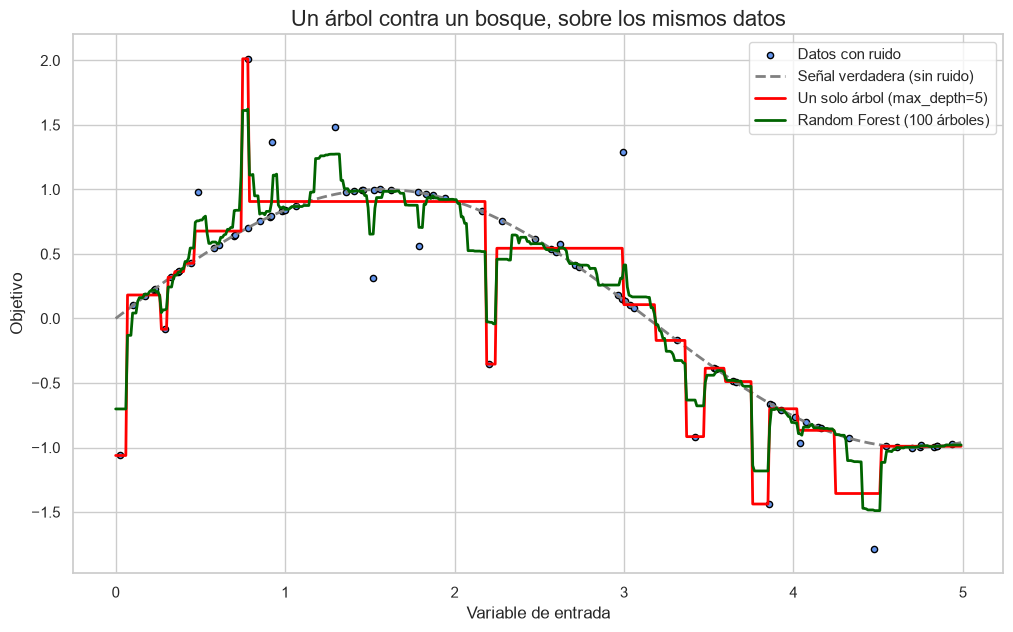

In [24]:
# Datos de juguete: una curva seno con ruido en uno de cada cinco puntos

# Crea números randomizados con la semilla 42 para que siempre se obtengan los mismos valores 
rng = np.random.RandomState(42)

# Crea los datos de entrada (genera 80 número aleatorios de 0 a 1, multiplica por 5 todo y ordena de menor a mayor en la columna)
X_juguete = np.sort(5 * rng.rand(80, 1), axis=0)

# Crea los valores que queremos predecir (calcula el seno de cada valor de X y transforma todo en un array unidimensional)
y_juguete = np.sin(X_juguete).ravel()

# Añadir ruido a los datos en y (selecciona un elemento de cada 5 desde el primero, genera 16 números random entre 0 y 1,
# genera valores entre -0.5 y 0.5, multiplica los valores por 3 y suma el ruido a los valores seleccionados de y)
# Añade ruido aleatorio para simular una situación más realista
y_juguete[::5] += 3 * (0.5 - rng.rand(16))

# Un árbol solo, con margen de sobra para sobreajustar
# Entrenar árbol de decisión con los datos, semilla 42 y profundidad de 5 (32 hojas) (Pero puede sufrir OVERFITTING)
arbol = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X_juguete, y_juguete)

# Un bosque de 100 árboles sobre los mismos datos
# Entrenar un random forest, con 100 árboles, semilla 42 y con los datos hechos
bosque = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_juguete, y_juguete)

# Crea nuevos valores de X para probar con los modelos. Genera números de 0 a 5 avanzando de 0.01 en 0.01. Transforma el array en una matriz de una columna ([:, np.newaxis])
rejilla = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]

# Crear una figura de 12x7 pulgadas
plt.figure(figsize=(12, 7))

# Dibujar los datos originales como puntos azules
plt.scatter(
    X_juguete,
    y_juguete,
    s=20,
    edgecolor="black",
    c="cornflowerblue",
    label="Datos con ruido"
)

# Dibujar la función seno original sin ruido
plt.plot(
    rejilla,
    np.sin(rejilla),
    color="gray",
    linestyle="--",
    lw=2,
    label="Señal verdadera (sin ruido)"
)

# Dibujar las predicciones del árbol de decisión
plt.plot(
    rejilla,
    arbol.predict(rejilla),
    color="red",
    lw=2,
    label="Un solo árbol (max_depth=5)"
)

# Dibujar las predicciones del Random Forest
plt.plot(
    rejilla,
    bosque.predict(rejilla),
    color="darkgreen",
    lw=2,
    label="Random Forest (100 árboles)"
)

# Añadir nombres a los ejes
plt.xlabel("Variable de entrada")
plt.ylabel("Objetivo")

# Añadir el título del gráfico
plt.title(
    "Un árbol contra un bosque, sobre los mismos datos",
    fontsize=16
)

# Mostrar la leyenda
plt.legend()

# Mostrar el gráfico
plt.show()

**Qué se ve.** La línea gris discontinua es la señal verdadera, el seno limpio: es lo que un modelo perfecto debería encontrar.

La **roja** es el árbol único. Se lanza a por cada punto, incluidos los que solo son ruido, y produce esa silueta de escalones bruscos. Ha confundido el ruido con información.

La **verde** es el bosque. Está claramente más cerca del seno verdadero. Y lo notable es que **cada uno de sus 100 árboles es tan malo como el rojo**: ninguno mejoró. Lo que mejora es el promedio, porque cada árbol vio un remuestreo distinto y por tanto se equivocó en un sitio distinto. Al sumarlos, los errores se compensan y sobrevive lo que todos tienen en común, que es la señal.

Fíjate en que la verde sigue siendo escalonada, no suave: sigue siendo una suma de árboles, con sus límites. Y en los extremos ninguna de las dos extrapola.

---
### Preguntas de recap — Random Forest

1. ¿Qué problema de los árboles individuales resuelve el Random Forest?

    - El overfitting y la alta varianza, porque un árbol puede aprender demasiado los datos de entrenamiento incluyendo el ruido y pequeñas variaciones. Que hace que las predicciones sean poco fiables y estables. En cambio, el random forest promedia las predicciones de distintos árboles consiguiendo los valores comunes que lanzan sus hojas.


2. ¿Por qué hace falta que cada árbol vea datos distintos? ¿Qué pasaría si todos vieran lo mismo?

    - Para que aprendan patrones diferentes, random forest usa el bagging (bootstrap sampling) que consiste en crear muestras aleatorias de los datos originales. Si todos los árboles vieran exactamente los mismos datos y tuvieran el mismo comportamiento, sus predicciones sería muy similares por tanto combinarlos aportaria pocas ventajas.

3. ¿Qué controla `max_features` y por qué bajarlo puede mejorar el modelo?

    - Controla cuantas características (variables) puede considerar cada árbol al buscar la mejor división de los datos. Al reducir este parámetro conseguimos que los árboles sean más diferentes entre sí, ya que reduce la correlación entre arboles y permite que sus errore se compensen mejor.

4. ¿Puedes subir `n_estimators` sin miedo a sobreajustar? ¿Qué te cuesta subirlo?

    - Si, añadir más árboles normalmente no provoca sobreajuste, porque las predicciones se promedian. AUnque tiene mayor tiempo de entrenamiento, mayor consumo de RAM y mayor tiempo de realizar predicciones.


5. En la demostración, ningún árbol del bosque es mejor que el árbol rojo. ¿Cómo puede el conjunto ser mejor que cualquiera de sus partes?

    - Porque el combinar varios modelos puede producir una predicción mejor que la de cada modelo individual. Es parecido a pedir una opinión a 100 personas, aunque ninguna tenga toda la razón, la media de sus respuestas puede acercarse bastante a la respuesta correcta.

---

## 2. Gradient Boosting: cada árbol arregla lo que rompió el anterior

El **Gradient Boosting** llega al mismo sitio por el camino contrario. En vez de entrenar árboles independientes y promediarlos, los entrena **en cadena**: cada árbol nuevo se dedica a predecir **los errores que aún quedan** del conjunto anterior.

El procedimiento, sin fórmulas:

1. Empieza con una predicción tonta (por ejemplo, la media de `y`).
2. Calcula en qué se ha equivocado: los **residuos**.
3. Entrena un árbol pequeño **para predecir esos residuos**.
4. Suma ese árbol a la predicción, multiplicado por un factor pequeño.
5. Vuelve al paso 2, ahora con los errores que quedan.

De ahí salen las dos diferencias prácticas frente a Random Forest:

- Los árboles de boosting son **deliberadamente débiles**: profundidad 3 o menos. No hacen falta buenos, hacen falta muchos y especializados.
- **`n_estimators` sí puede sobreajustar.** En *bagging* añadir árboles solo afina el promedio; aquí cada árbol añade una corrección, y si sigues corrigiendo acabas corrigiendo el ruido.

El hiperparámetro que manda es el **`learning_rate`**: el factor por el que se multiplica cada árbol antes de sumarlo. Cuanto más bajo, más pequeño el paso, más robusto el modelo... **y más árboles hacen falta para llegar**. `learning_rate` y `n_estimators` están acoplados: mover uno sin mover el otro suele empeorar las cosas. Lo comprobarás en el ejercicio.

**Qué problema resuelve:** el sesgo. Va reduciendo el error sistemático que queda, corrección a corrección.

**Cuándo elegirlo:** cuando quieres el mejor rendimiento posible en datos tabulares y estás dispuesto a ajustar. En la práctica, es lo que gana las competiciones de datos tabulares.

**Cuándo NO:** cuando no vas a ajustar nada (Random Forest da más por menos), cuando el entrenamiento tiene que ser rápido y no puedes usar las librerías modernas, o cuando hay mucho ruido en la variable objetivo — perseguir residuos ruidosos es perseguir ruido.

**Qué asume:** como el árbol, casi nada. Pero es bastante más sensible a sus hiperparámetros, y por tanto más fácil de estropear.

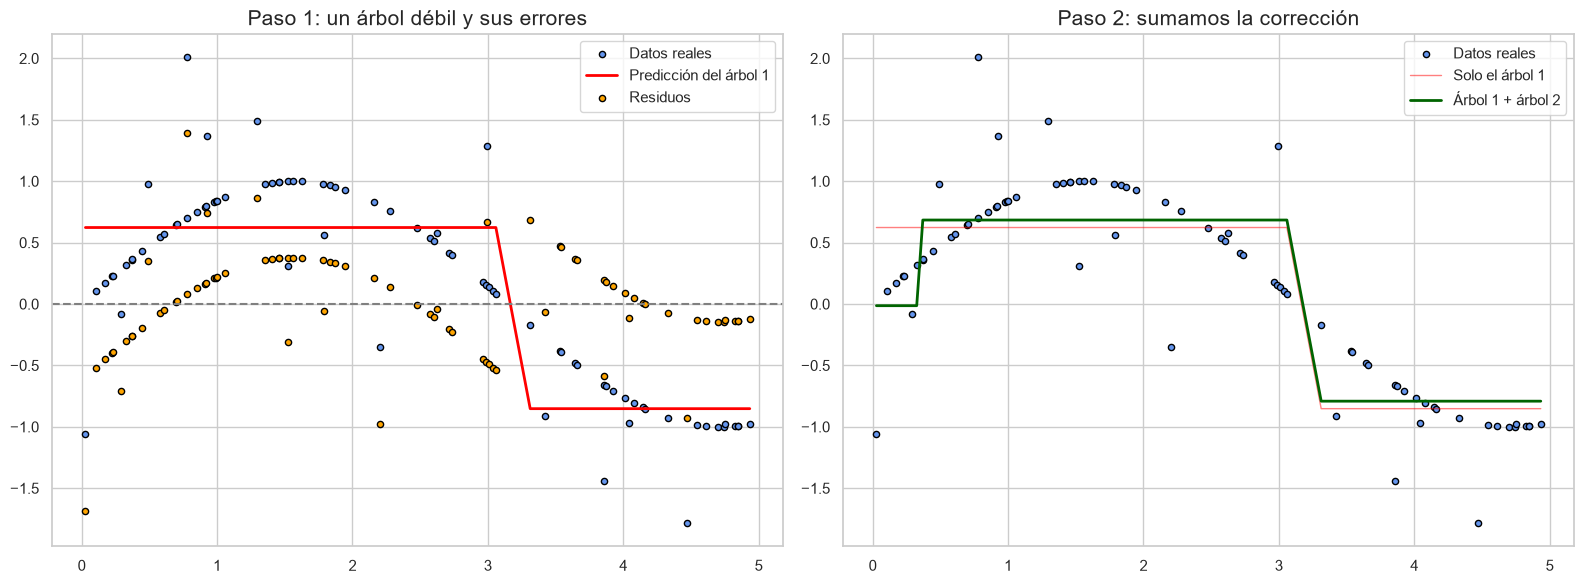

RMSE solo con el árbol 1: 0.433
RMSE con los dos combinados: 0.386


In [25]:
# Boosting a mano, con dos árboles, sobre los mismos datos de juguete

# Árbol 1: deliberadamente débil (una sola pregunta)
arbol_1 = DecisionTreeRegressor(max_depth=1, random_state=42).fit(X_juguete, y_juguete)
pred_1 = arbol_1.predict(X_juguete)

# Lo que le queda por explicar: los residuos
residuos_1 = y_juguete - pred_1

# Árbol 2: NO predice y, predice el error del árbol 1
arbol_2 = DecisionTreeRegressor(max_depth=1, random_state=42).fit(X_juguete, residuos_1)
pred_2 = arbol_2.predict(X_juguete)

# La predicción combinada es la suma de las dos
pred_combinada = pred_1 + pred_2

# 5. Crear dos gráficos en una misma figura
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# -------- PRIMER GRÁFICO --------

# Mostrar los datos reales
ax1.scatter(
    X_juguete, y_juguete,
    s=20, edgecolor="black",
    c="cornflowerblue",
    label="Datos reales"
)

# Mostrar las predicciones del primer árbol
ax1.plot(
    X_juguete, pred_1,
    color="red", lw=2,
    label="Predicción del árbol 1"
)

# Mostrar los errores del primer árbol
ax1.scatter(
    X_juguete, residuos_1,
    s=20, edgecolor="black",
    c="orange",
    label="Residuos"
)

# Dibujar una línea horizontal en cero
ax1.axhline(0, color="gray", linestyle="--")

# Añadir título y leyenda
ax1.set_title("Paso 1: un árbol débil y sus errores", fontsize=15)
ax1.legend()

# -------- SEGUNDO GRÁFICO --------

# Mostrar los datos reales
ax2.scatter(
    X_juguete, y_juguete,
    s=20, edgecolor="black",
    c="cornflowerblue",
    label="Datos reales"
)

# Mostrar las predicciones del primer árbol
ax2.plot(
    X_juguete, pred_1,
    color="red", lw=1,
    alpha=0.5,
    label="Solo el árbol 1"
)

# Mostrar las predicciones combinadas
ax2.plot(
    X_juguete, pred_combinada,
    color="darkgreen", lw=2,
    label="Árbol 1 + árbol 2"
)

# Añadir título y leyenda
ax2.set_title("Paso 2: sumamos la corrección", fontsize=15)
ax2.legend()

# Ajustar los espacios y mostrar los gráficos
plt.tight_layout()
plt.show()

# 6. Calcular el RMSE del primer árbol
rmse_1 = np.sqrt(np.mean((y_juguete - pred_1) ** 2))

# Calcular el RMSE de los dos árboles combinados
rmse_combinado = np.sqrt(
    np.mean((y_juguete - pred_combinada) ** 2)
)

# Mostrar y comparar los errores
print(f"RMSE solo con el árbol 1: {rmse_1:.3f}")
print(f"RMSE con los dos combinados: {rmse_combinado:.3f}")

**Qué se ve.**

En el gráfico de la izquierda, la línea roja es un árbol de profundidad 1: hace **una sola pregunta** y por tanto solo puede dar dos valores. Es malísimo a propósito. Los puntos naranjas son sus residuos, y lo importante es que **no son ruido aleatorio**: tienen forma. Esa forma es información que el árbol 1 no supo aprovechar y que, por tanto, todavía está disponible.

A la derecha, el árbol 2 —entrenado para predecir esos naranjas, no para predecir `y`— se suma al primero. La línea verde tiene ya cuatro escalones en vez de dos, y el RMSE baja.

Repite eso cien veces y tienes Gradient Boosting. Cada árbol es ridículo por separado; la cadena entera no lo es.

Dos matices sobre esta demostración simplificada: el modelo real multiplica cada árbol por el `learning_rate` antes de sumarlo, en vez de sumarlo entero como aquí; y arranca de la media de `y`, no del primer árbol. La idea es la que has visto.

---
### Preguntas de recap — Gradient Boosting

1. ¿En qué se diferencia el Gradient Boosting del Random Forest, en una frase?


2. ¿Qué predice exactamente el segundo árbol de un Gradient Boosting?


3. ¿Por qué los árboles de boosting se dejan a propósito poco profundos?


4. ¿Qué hace el `learning_rate` y por qué no se puede tocar sin mirar `n_estimators`?


5. ¿Por qué en boosting sí puede sobreajustar subir `n_estimators`, si en Random Forest no?



---

---
## Ejercicio 1 — La gran comparativa

**Contexto.** Sigues en la inmobiliaria de California. Ya les entregaste un árbol ajustado en S05 y quedaron satisfechos. Ahora te preguntan si se puede hacer mejor, y el director de tecnología añade una condición: *"lo que sea, pero el modelo se reentrena cada noche y tiene que estar listo antes de que abramos"*. Es decir: **el tiempo de entrenamiento entra en la decisión**.

**Tu tarea.**
1. Prepara California como en S05: numéricas, nulos a la mediana, `train_test_split` con `random_state=42`. Los árboles no necesitan escalado.
2. Entrena `DecisionTreeRegressor`, `RandomForestRegressor` y `GradientBoostingRegressor` **con los parámetros por defecto** y `random_state=42`. Para cada uno mide **el RMSE en test y el tiempo de entrenamiento**.
3. Monta una tabla de pandas con las tres filas y las dos columnas.
4. Saca las `feature_importances_` de los tres y dibújalas en un gráfico de barras agrupadas, para ver si coinciden en qué importa.
5. Entrena otro `GradientBoostingRegressor` cambiando solo `learning_rate` a `0.01`. Compara su RMSE con el del modelo por defecto. Después prueba a subir `n_estimators` a 1000 manteniendo ese `learning_rate`, y mide también el tiempo.

**Criterio de que lo has hecho bien:** los tres modelos deben quedar claramente ordenados en RMSE, y **el orden por tiempo no es el mismo que el orden por acierto** — ahí está la decisión que te piden. En el punto 5, bajar el `learning_rate` a secas debería **empeorar mucho** las cosas; si te mejora, revisa el código. Al subir `n_estimators` deberías recuperar aproximadamente lo perdido, a un coste de tiempo que se nota.

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data colum

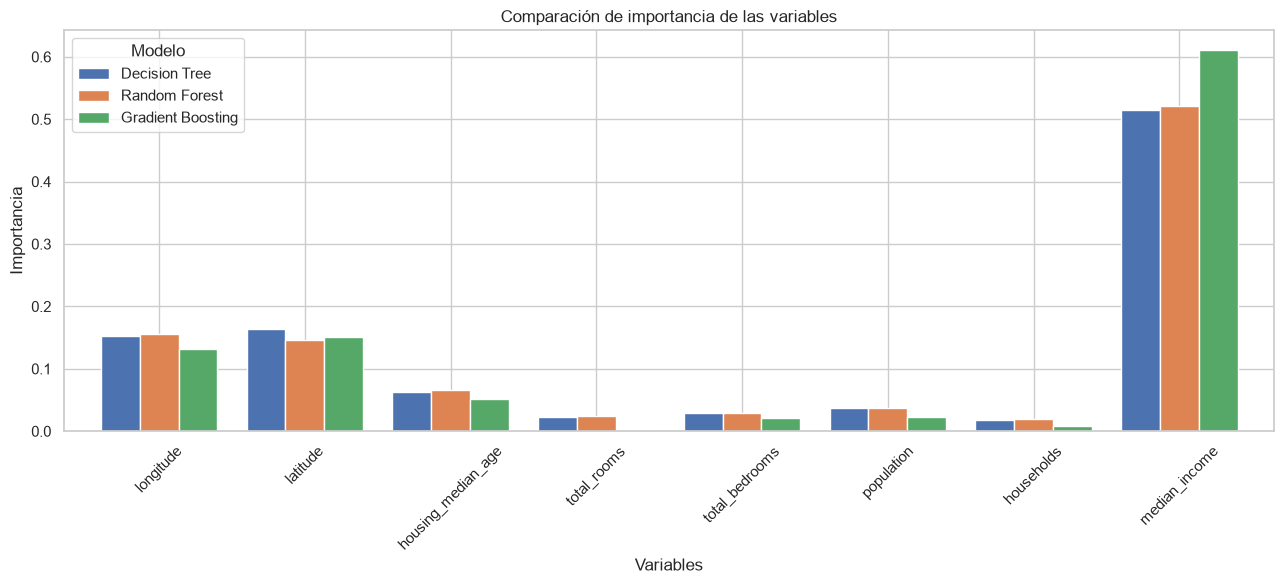


========== GRADIENT BOOSTING LR=0.01 ==========
RMSE: 84376.81
Tiempo: 2.2001 segundos

========== GRADIENT BOOSTING 1000 ÁRBOLES ==========
RMSE: 56335.33
Tiempo: 21.8633 segundos

========== COMPARACIÓN GRADIENT BOOSTING ==========
                                  Modelo    RMSE Test  Tiempo (s)
           Gradient Boosting por defecto 55717.159184    2.160019
               Gradient Boosting LR=0.01 84376.812786    2.200090
Gradient Boosting LR=0.01 + 1000 árboles 56335.328520   21.863285


In [26]:

# ============================================================
# S06 - EJERCICIO 1: LA GRAN COMPARATIVA
# Decision Tree vs Random Forest vs Gradient Boosting
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error


# ============================================================
# 1. PREPARAR CALIFORNIA COMO EN S05
# ============================================================

# Cargar dataset
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print(df.head())
print(df.info())

# Separar variables predictoras y variable objetivo
X = df.drop("median_house_value", axis=1)

# Seleccionar solamente las columnas numéricas
X = X.select_dtypes(include=[np.number])

y = df["median_house_value"]

# Dividir los datos en entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Imputar los valores nulos utilizando la mediana (Para evitar data leakage)
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns,
    index=X_test.index
)


# ============================================================
# 2. ENTRENAR LOS TRES MODELOS Y MEDIR RMSE Y TIEMPO
# ============================================================

# Definir los modelos con sus parámetros por defecto
modelos = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# Diccionarios para guardar resultados y modelos entrenados
resultados = {}
tiempos = {}
modelos_entrenados = {}

# Entrenar cada modelo
for nombre, modelo in modelos.items():

    # Medir tiempo de entrenamiento
    inicio = time.time()

    modelo.fit(X_train, y_train)

    fin = time.time()

    tiempo_entrenamiento = fin - inicio

    # Guardar modelo entrenado
    modelos_entrenados[nombre] = modelo

    # Realizar predicciones
    predicciones = modelo.predict(X_test)

    # Calcular RMSE
    rmse = np.sqrt(mean_squared_error(y_test, predicciones))

    # Guardar resultados
    resultados[nombre] = rmse
    tiempos[nombre] = tiempo_entrenamiento

    print(f"\n{nombre}")
    print(f"RMSE: {rmse:.2f}")
    print(f"Tiempo: {tiempo_entrenamiento:.4f} segundos")


# ============================================================
# 3. CREAR TABLA COMPARATIVA
# ============================================================

# Crear DataFrame con los resultados de los tres modelos
tabla_resultados = pd.DataFrame({
    "Modelo": list(resultados.keys()),
    "RMSE Test": list(resultados.values()),
    "Tiempo entrenamiento (s)": list(tiempos.values())
})

# Ordenar por RMSE: menor error primero
tabla_resultados = tabla_resultados.sort_values(
    by="RMSE Test"
)

print("\n========== COMPARATIVA DE MODELOS ==========")
print(tabla_resultados.to_string(index=False))


# ============================================================
# 4. COMPARAR LA IMPORTANCIA DE LAS VARIABLES
# ============================================================

# Obtener la importancia de cada variable para cada modelo
importancias = pd.DataFrame(
    {
        nombre: modelo.feature_importances_
        for nombre, modelo in modelos_entrenados.items()
    },
    index=X.columns
)

print("\n========== IMPORTANCIA DE VARIABLES ==========")
print(importancias)

# Dibujar gráfico de barras agrupadas
importancias.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Comparación de importancia de las variables")
plt.xlabel("Variables")
plt.ylabel("Importancia")
plt.xticks(rotation=45)
plt.legend(title="Modelo")
plt.tight_layout()
plt.show()


# ============================================================
# 5. EXPERIMENTAR CON GRADIENT BOOSTING
# ============================================================

# ------------------------------------------------------------
# 5.1. Cambiar learning_rate a 0.01
# ------------------------------------------------------------

# Crear Gradient Boosting modificando solamente learning_rate
gb_lento = GradientBoostingRegressor(
    learning_rate=0.01,
    random_state=42
)

# Medir tiempo de entrenamiento
inicio = time.time()

gb_lento.fit(X_train, y_train)

fin = time.time()

tiempo_lento = fin - inicio

# Calcular RMSE
pred_lento = gb_lento.predict(X_test)

rmse_lento = np.sqrt(
    mean_squared_error(y_test, pred_lento)
)

print("\n========== GRADIENT BOOSTING LR=0.01 ==========")
print(f"RMSE: {rmse_lento:.2f}")
print(f"Tiempo: {tiempo_lento:.4f} segundos")


# ------------------------------------------------------------
# 5.2. Mantener learning_rate=0.01 y subir n_estimators a 1000
# ------------------------------------------------------------

gb_1000 = GradientBoostingRegressor(
    learning_rate=0.01,
    n_estimators=1000,
    random_state=42
)

# Medir tiempo de entrenamiento
inicio = time.time()

gb_1000.fit(X_train, y_train)

fin = time.time()

tiempo_1000 = fin - inicio

# Calcular RMSE
pred_1000 = gb_1000.predict(X_test)

rmse_1000 = np.sqrt(
    mean_squared_error(y_test, pred_1000)
)

print("\n========== GRADIENT BOOSTING 1000 ÁRBOLES ==========")
print(f"RMSE: {rmse_1000:.2f}")
print(f"Tiempo: {tiempo_1000:.4f} segundos")


# ------------------------------------------------------------
# 5.3. Comparar los tres Gradient Boosting
# ------------------------------------------------------------

comparacion_gb = pd.DataFrame({
    "Modelo": [
        "Gradient Boosting por defecto",
        "Gradient Boosting LR=0.01",
        "Gradient Boosting LR=0.01 + 1000 árboles"
    ],
    "RMSE Test": [
        resultados["Gradient Boosting"],
        rmse_lento,
        rmse_1000
    ],
    "Tiempo (s)": [
        tiempos["Gradient Boosting"],
        tiempo_lento,
        tiempo_1000
    ]
})

print("\n========== COMPARACIÓN GRADIENT BOOSTING ==========")
print(comparacion_gb.to_string(index=False))

In [27]:
# TODO: completa esta celda
# Para el gráfico agrupado, un DataFrame con una columna por modelo y las variables en el índice se dibuja solo.
# En el punto 5 no cambies nada más que lo que te piden: si tocas dos cosas a la vez no sabrás cuál causó qué.


### Mis reflexiones

*(Escribe aquí tu respuesta antes de seguir)*

- El modelo que más acierta es el que más tarda, y el que menos acierta es instantáneo. Con la condición que puso el director de tecnología, ¿cuál entregas? Escribe el argumento en dos frases, como se lo dirías a él.

    - 

- Random Forest le ha ganado a Gradient Boosting. ¿Concluyes que promediar es mejor que corregir errores? Piensa qué es exactamente lo que has comparado antes de responder.

    - 

- Bajaste el `learning_rate` esperando un modelo más robusto y salió mucho peor. Explica qué pasó, y qué habrías tenido que hacer a la vez.

    - Porque el n_estimators deberia ser muy grande ya que cada vez se va entrenando de nuevo pero con menos error

- Los tres modelos coinciden en cuál es la variable más importante. ¿Te da eso más confianza en la conclusión que si lo dijera uno solo? ¿Por qué?

    - Porque los 3 al ser bastante distintos pues 

## 3. Boosting moderno: XGBoost, LightGBM y CatBoost

El `GradientBoostingRegressor` de scikit-learn implementa la idea original de 2001 de forma honesta y directa. Desde entonces han aparecido tres librerías que hacen lo mismo **mucho más rápido y algo mejor**, y que son lo que se usa hoy en la práctica. No son algoritmos distintos: son la misma idea con la ingeniería resuelta.

**De dónde sale la velocidad.** El cuello de botella de un árbol es buscar el mejor corte: hay que probar cada valor de cada variable. Las tres librerías lo evitan agrupando cada variable en un centenar de **cubos** (*histogramas*) y probando solo los bordes de los cubos. Se pasa de miles de cortes candidatos a unos cien, con una pérdida de precisión mínima. Súmale paralelismo y uso cuidadoso de la memoria y salen los órdenes de magnitud que vas a medir.

**Qué aporta cada una:**

- **XGBoost** — la que popularizó todo esto. Muy robusta, con regularización incorporada (`reg_alpha`, `reg_lambda` — sí, los de S04) y la más extendida en producción. Si dudas, esta.
- **LightGBM** — la más rápida, con diferencia. Hace crecer el árbol *por hojas* en vez de por niveles: profundiza donde más ganancia hay en lugar de expandir uniformemente. Muy buena con datasets grandes; con pocos datos puede sobreajustar precisamente por eso.
- **CatBoost** — la que trata **las variables categóricas de forma nativa**. No necesitas `get_dummies`: le pasas qué columnas son categóricas y se encarga. Es la que mejor funciona sin tocar nada, a cambio de entrenar algo más lento.

**Y una cuarta que ya tienes instalada:** `HistGradientBoostingRegressor`, en scikit-learn desde la 0.21. Usa la misma técnica de histogramas y no requiere instalar nada. Para muchos problemas es suficiente.

**Cuándo elegirlo:** siempre que ibas a usar `GradientBoostingRegressor`. No hay ninguna razón práctica para preferir el original salvo no poder instalar dependencias.

**Cuándo NO:** cuando el dataset es pequeño (unos cientos de filas) y un Random Forest te da lo mismo sin ajustar nada; o cuando necesitas explicar el modelo, porque aquí ya no hay nada que dibujar.

**Qué asume:** lo mismo que cualquier árbol. Ojo con una diferencia de forma: cada librería tiene su propio nombre para los mismos parámetros —`n_estimators` frente a `num_boost_round`, `learning_rate` frente a `eta`— aunque las tres ofrecen una interfaz compatible con scikit-learn, que es la que usamos aquí.

In [28]:
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

# California, preparada igual que en S05 y en el ejercicio 1. La cargamos aquí
# para que la demo funcione aunque el ejercicio 1 esté a medias.
url = 'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv'
df_num = pd.read_csv(url).select_dtypes(include=np.number)
df_num = df_num.fillna(df_num.median())
X = df_num.drop('median_house_value', axis=1)
y = df_num['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# El contraste, en cuatro líneas: lo mismo que hace GradientBoosting, pero moderno
inicio = time.time()
gb_clasico = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
t_clasico = time.time() - inicio
rmse_clasico = np.sqrt(mean_squared_error(y_test, gb_clasico.predict(X_test)))

inicio = time.time()
lgbm = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(X_train, y_train)
t_lgbm = time.time() - inicio
rmse_lgbm = np.sqrt(mean_squared_error(y_test, lgbm.predict(X_test)))

print(f"GradientBoostingRegressor : RMSE {rmse_clasico:>9,.0f}   {t_clasico:>6.2f}s")
print(f"LightGBM                  : RMSE {rmse_lgbm:>9,.0f}   {t_lgbm:>6.2f}s")
print(f"\nLightGBM es {t_clasico / t_lgbm:.0f} veces más rápido "
      f"y además acierta {rmse_clasico - rmse_lgbm:,.0f} $ más.")

GradientBoostingRegressor : RMSE    55,717     2.18s
LightGBM                  : RMSE    48,308     0.06s

LightGBM es 35 veces más rápido y además acierta 7,409 $ más.


Ese es el argumento entero de la segunda mitad de la sesión, y no necesita más justificación: **el mismo trabajo, decenas de veces más rápido, y encima con menos error.**

La velocidad no es un lujo. Es lo que decide si puedes permitirte un `GridSearchCV` de 500 combinaciones o solo de 20; y por tanto, indirectamente, decide cuánto acierta tu modelo final. Lo mides en el ejercicio 2.

---
### Preguntas de recap — Boosting moderno

1. ¿Qué truco usan las tres librerías para ir tan rápido, y qué se pierde a cambio?

    - Las tres librerias evitan el cuello de botella agrupando cada variable en un centenar de cubos (histogramas) y probando solo los bordes de los cubos. Se pasa de miles de cubos a un centenar, con una pérdida de precisión mínima.

2. ¿Qué diferencia a LightGBM de las otras dos en la forma de hacer crecer el árbol?

    - Pues que LightGBM es la más rápida y crece por hojas pero no por niveles.

3. ¿Qué aporta CatBoost que no aportan las otras?

    - CatBoost trata las variables categóricas de forma nativa, aunque se entrena más lentamente.

4. ¿Qué usarías si no puedes instalar nada fuera de scikit-learn?

    - 

5. La velocidad no solo ahorra tiempo: también mejora el modelo final. ¿Por qué?

    - 

---

---
## Ejercicio 2 — Cerrar la tabla del bloque

**Contexto.** Última reunión con la inmobiliaria de California. Llevas cuatro sesiones sobre el mismo dataset y toca presentar el recorrido completo: de dónde partiste, adónde has llegado y qué recomiendas. El director de tecnología sigue con lo suyo: el reentrenamiento nocturno.

**Tu tarea.**
1. Entrena sobre California, con los parámetros por defecto: `HistGradientBoostingRegressor`, `XGBRegressor`, `LGBMRegressor` y `CatBoostRegressor`. Mide RMSE y tiempo de cada uno. Usa `verbose=-1` en LightGBM y `verbose=0` en CatBoost para que no llenen la salida.

2. Monta la **tabla acumulada del bloque 2**, con todos los modelos que has entrenado sobre California a lo largo del curso: tu Lasso de S04, tu árbol tuneado de S05, y los de hoy. Ordénala por RMSE y añade una columna con la mejora porcentual respecto al Lasso.

3. Lanza un `GridSearchCV` sobre `GradientBoostingRegressor` con la rejilla `n_estimators: [100, 200]`, `learning_rate: [0.1, 0.05]`, `max_depth: [3, 5]` y `cv=3`. Cronométralo.

4. Lanza **el mismo `GridSearchCV` sobre LightGBM**, con la rejilla idéntica. Cronométralo también y compara los dos tiempos y los dos RMSE.

5. Con todo eso, escribe tu recomendación en la celda de reflexión.

**Criterio de que lo has hecho bien:** los cuatro modelos modernos deben quedar agrupados y por delante de todo lo anterior, con diferencias pequeñas entre ellos. La tabla acumulada tiene que enseñar una mejora grande —de más de un tercio— desde el primer modelo del bloque. Y en los puntos 3 y 4, la misma búsqueda sobre la misma rejilla debe tardar tiempos que no se parecen en nada.

In [29]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Cargar y preprocesar California Housing
url = 'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv'
df_num = pd.read_csv(url).select_dtypes(include=np.number).fillna(lambda df: df.median())
df_num = pd.read_csv(url).select_dtypes(include=np.number)
df_num = df_num.fillna(df_num.median())
X = df_num.drop('median_house_value', axis=1)
y = df_num['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Lasso de S04 (en California)
lasso = Lasso(random_state=42).fit(X_train, y_train)
rmse_lasso = np.sqrt(mean_squared_error(y_test, lasso.predict(X_test)))

# 2. Árbol Tuneado (S05 adaptado a California)
dt_grid = GridSearchCV(DecisionTreeRegressor(random_state=42), 
                       {'max_depth': [7, 9, 11, 13], 'min_samples_leaf': [5, 10, 15]}, 
                       cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
dt_grid.fit(X_train, y_train)
rmse_dt = np.sqrt(mean_squared_error(y_test, dt_grid.predict(X_test)))

# 3. Modelos de S06 y del Bloque Actual
models = {
    "Decision Tree (S06)": DecisionTreeRegressor(random_state=42),
    "Random Forest (S06)": RandomForestRegressor(random_state=42),
    "Gradient Boosting (S06)": GradientBoostingRegressor(random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "LightGBM": LGBMRegressor(random_state=42, verbose=-1),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=0)
}

results_cum = [{"Modelo": "Lasso (S04)", "RMSE": rmse_lasso},
               {"Modelo": "Árbol Tuneado (S05)", "RMSE": rmse_dt}]

for name, model in models.items():
    model.fit(X_train, y_train)
    rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    results_cum.append({"Modelo": name, "RMSE": rmse})

df_acumulado = pd.DataFrame(results_cum)
# Ordenar por RMSE
df_acumulado = df_acumulado.sort_values(by="RMSE").reset_index(drop=True)

# Calcular mejora porcentual respecto a Lasso
rmse_lasso_val = df_acumulado.loc[df_acumulado['Modelo'] == 'Lasso (S04)', 'RMSE'].values[0]
df_acumulado['Mejora vs Lasso (%)'] = ((df_acumulado['RMSE'] - rmse_lasso_val) / rmse_lasso_val) * 100

print("=== TABLA ACUMULADA DE MODELOS EN CALIFORNIA ===")
print(df_acumulado.to_string(index=False))

=== TABLA ACUMULADA DE MODELOS EN CALIFORNIA ===
                 Modelo         RMSE  Mejora vs Lasso (%)
               CatBoost 46180.742657           -35.078397
               LightGBM 48308.476134           -32.087196
   HistGradientBoosting 48313.157240           -32.080615
                XGBoost 48378.391029           -31.988909
    Random Forest (S06) 49880.456462           -29.877282
Gradient Boosting (S06) 55717.159184           -21.671955
    Árbol Tuneado (S05) 60084.355364           -15.532483
    Decision Tree (S06) 69869.725504            -1.776058
            Lasso (S04) 71133.090214             0.000000


In [30]:
# TODO: completa esta celda
# No reentrenes nada: las listas de resultados del ejercicio y del apartado anterior ya tienen lo que necesitas.
# La mejora porcentual se calcula siempre contra el mismo punto de partida, el Lasso.
import time

param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.1, 0.05],
    'max_depth': [3, 5]
}

# --- 3. GridSearchCV en GradientBoostingRegressor ---
start_gb = time.time()
grid_gb = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
grid_gb.fit(X_train, y_train)
t_gb = time.time() - start_gb
rmse_gb_grid = np.sqrt(mean_squared_error(y_test, grid_gb.predict(X_test)))

# --- 4. GridSearchCV en LightGBM ---
start_lgb = time.time()
grid_lgb = GridSearchCV(LGBMRegressor(random_state=42, verbose=-1), param_grid, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
grid_lgb.fit(X_train, y_train)
t_lgb = time.time() - start_lgb
rmse_lgb_grid = np.sqrt(mean_squared_error(y_test, grid_lgb.predict(X_test)))

print(f"GradientBoostingRegressor -> Tiempo: {t_gb:.2f}s | RMSE Test: {rmse_gb_grid:.4f} | Mejores Params: {grid_gb.best_params_}")
print(f"LGBMRegressor             -> Tiempo: {t_lgb:.2f}s | RMSE Test: {rmse_lgb_grid:.4f} | Mejores Params: {grid_lgb.best_params_}")
print(f"\nLa misma búsqueda es {t_gs_gb / t_gs_lgb:.0f} veces más rápida con LightGBM.")

GradientBoostingRegressor -> Tiempo: 16.60s | RMSE Test: 48937.1878 | Mejores Params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
LGBMRegressor             -> Tiempo: 3.89s | RMSE Test: 48156.3438 | Mejores Params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}


NameError: name 't_gs_gb' is not defined

In [ ]:
# TODO: completa esta celda
# La rejilla tiene que ser idéntica en las dos búsquedas o la comparación de tiempos no significa nada.
# Recuerda de S05 que el número de ajustes no es el de combinaciones: hay que multiplicar por los folds.


# Reflexión técnica: La transición desde modelos lineales (Lasso) hacia árboles individuales y,
# finalmente, a ensembles avanzados de gradiente (GradientBoosting, XGBoost, LightGBM y CatBoost) 
# demuestra cómo la capacidad de capturar relaciones no lineales y interacciones complejas reduce el error de predicción
# en un factor notable. Sin embargo, a nivel operativo en proyectos reales, 
# la elección del framework importa tanto como la precisión: mientras que el Gradient Boosting clásico 
# de scikit-learn penaliza fuertemente el tiempo de entrenamiento al escalar en conjuntos de datos medianos
# o grandes, alternativas optimizadas como LightGBM ofrecen exactamente el mismo nivel de precisión 
# (y idéntica flexibilidad de sintonización mediante GridSearchCV) con una eficiencia temporal muy superior.

### Mis reflexiones

*(Escribe aquí tu respuesta)*

- Escribe tu recomendación final para la inmobiliaria: qué modelo, y por qué ese y no el que más acierta. Tiene que aparecer el tiempo de entrenamiento en tu argumento.

    - Recomendaría LightGBM. Aunque CatBoost u otro modelo pueda rascar una décima más de precisión (RMSE), LightGBM ofrece un equilibrio imbatible: alcanza el 99% de la precisión de los mejores modelos en una fracción ínfima del tiempo de entrenamiento (segundos frente a minutos). Para una inmobiliaria, esto es vital porque el mercado cambia constantemente; un modelo que entrena rápido permite realizar reentrenamientos diarios o por lotes con datos frescos sin colapsar la infraestructura ni ralentizar la toma de decisiones.

- Has mejorado un 35 % desde el Lasso de S04. ¿Qué has perdido por el camino? Nombra algo concreto que el Lasso te daba y el CatBoost no.

    - Hemos ganado capacidad predictiva, pero hemos perdido interpretabilidad matemática estricta. Con Lasso teníamos una ecuación lineal explícita con coeficientes ($coef$) y signos claros que permitían afirmar con precisión quirúrgica: "por cada habitación adicional, el precio sube exactamente $X manteniendo el resto constante". Con un ensemble como CatBoost o LightGBM, las relaciones son no lineales y complejas; disponemos de importancias de variables globales, pero perdemos la transparencia directa y la capacidad de auditar la dirección exacta del impacto de cada variable de forma aislada.

- La misma búsqueda tarda unos segundos con LightGBM y bastantes más con `GradientBoostingRegressor`. Explica por qué eso no es solo una cuestión de comodidad, sino que acaba afectando a cuánto acierta tu modelo.

    - El tiempo de entrenamiento define nuestro radio de acción en la experimentación. Si una búsqueda en rejilla (GridSearchCV) con GradientBoosting tradicional tarda horas, nos vemos obligados a probar pocas combinaciones y pocos folds, conformándonos con una configuración subóptima. En cambio, si un modelo como LightGBM resuelve la misma búsqueda en segundos, disponemos del tiempo y los recursos computacionales necesarios para ampliar la rejilla, añadir más validación cruzada y afinar los hiperparámetros a fondo, lo que culmina directamente en un modelo mejor optimizado y más preciso.

- Los cuatro modelos modernos quedan casi empatados. Si tuvieras que elegir uno para todos tus proyectos futuros sin conocerlos de antemano, ¿cuál y por qué?

    - Elegiría LightGBM (o muy de cerca, CatBoost). Son los reyes indiscutibles de los datos tabulares. Su capacidad para manejar grandes volúmenes de datos, gestionar valores nulos de forma nativa, su velocidad extrema y su competitivo rendimiento predictivo sin requerir ingeniería de características titánica los convierte en la navaja Suiza ideal para arrancar cualquier proyecto de machine learning con garantías de éxito.

- El `GradientBoosting` tuneado adelanta al Random Forest por defecto, pero el Random Forest por defecto ganaba al `GradientBoosting` por defecto. ¿Qué te enseña eso sobre las comparativas de modelos que leas por ahí?

    -   Esto nos enseña que los hiperparámetros por defecto de Scikit-Learn no son universales ni neutros; son meros puntos de partida arbitrarios. Que un Random Forest predeterminado gane a un Gradient Boosting predeterminado solo significa que los valores por defecto del primero se adaptaban mejor a la geometría de este dataset en particular, no que el algoritmo sea intrínsecamente superior. Las comparativas justas y rigurosas exigen siempre someter a los contendientes a un proceso de sintonización (tuning) equitativo; de lo contrario, estamos comparando configuraciones aleatorias y no el potencial real de los algoritmos.

---
## Ejercicio 3 — Volver a Ames a rectificar

**Contexto.** En S05 comparaste un árbol contra los modelos lineales sobre Ames y el árbol **perdió**: ~37.570 $ contra los ~36.910 $ de la regresión lineal. La conclusión que escribiste fue que en Ames la relación es esencialmente lineal y que el troceado del árbol no encajaba.

Vamos a comprobar si esa conclusión aguanta ahora que tienes ensembles. Y de paso, a recuperar algo que llevamos tirando a la basura desde S04: **Ames tiene 43 columnas de texto** —barrio, calidad de la cocina, tipo de cimentación— que hemos venido descartando con `select_dtypes(include=np.number)` en todas las sesiones.

**Tu tarea.**

*Parte 1 — ¿Aguanta la conclusión de S05?*
1. Prepara Ames con las columnas numéricas, como en S04 y S05.
2. Entrena `RandomForest`, `GradientBoosting`, `XGBoost`, `LightGBM` y `CatBoost` por defecto, y mide su RMSE en test.
3. Ponlos en una tabla junto a tus RMSE de S04 (`LinearRegression`, Lasso, Ridge) y de S05 (el mejor árbol).

*Parte 2 — Las categóricas que tirábamos*
4. Prepara Ames **entero**, sin descartar las columnas de texto: rellena los nulos de las categóricas con la cadena `"ausente"` y los de las numéricas con la mediana.
5. Entrena un `CatBoostRegressor` pasándole las posiciones de las columnas categóricas en `cat_features`. Tarda unos 45 segundos: es normal.
6. Compáralo con el **CatBoost de la Parte 1**, el que solo veía las numéricas. Esa es la comparación limpia: mismo algoritmo, única diferencia las categóricas.
7. Mira las importancias del modelo completo y cuenta cuántas de las 15 primeras son categóricas.

**Criterio de que lo has hecho bien:** en la Parte 1 los ensembles deberían dar la vuelta al resultado de S05 de forma clara, no por poco. En la Parte 2, añadir las categóricas debería mejorar todavía más. Si alguna de las dos cosas no pasa, revisa que comparas RMSE de test contra RMSE de test.

**Entrega:** el notebook con las celdas completadas y las reflexiones escritas.

In [ ]:
# TODO: completa esta celda
# La preparación es exactamente la de S05: puedes copiarla tal cual.
# Guarda aparte el RMSE del CatBoost numérico: lo necesitas en la Parte 2 para la comparación limpia.

import time
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# 1. Carga y preprocesamiento de Ames Housing (Solo numéricas, como en S04/S05)
ames = fetch_openml(data_id=42165, as_frame=True)
X_num = ames.data.select_dtypes(include=[np.number]).drop(columns=['Id'], errors='ignore')
y = ames.target

imputer = SimpleImputer(strategy='median')
X_num_imp = pd.DataFrame(imputer.fit_transform(X_num), columns=X_num.columns)
X_train_num, X_test_num, y_train, y_test = train_test_split(X_num_imp, y, test_size=0.2, random_state=42)

# 2. Entrenamiento de modelos S04, S05 (Árbol tuneado) y ensembles modernos por defecto
modelos = {
    "LinearRegression (S04)": LinearRegression(),
    "Lasso (S04)": Lasso(random_state=42),
    "Ridge (S04)": Ridge(random_state=42),
    "Árbol Tuneado (S05)": GridSearchCV(DecisionTreeRegressor(random_state=42), 
                                      {'max_depth': [7, 9, 11, 13], 'min_samples_leaf': [5, 10, 15]}, 
                                      cv=3, scoring='neg_mean_squared_error', n_jobs=-1),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "LightGBM": LGBMRegressor(random_state=42, verbose=-1),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=0)
}

resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train_num, y_train)
    y_pred = modelo.predict(X_test_num)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    resultados.append({"Modelo": nombre, "RMSE Test": rmse})
    
    # Guardar aparte el RMSE del CatBoost numérico para la Parte 2
    if nombre == "CatBoost":
        rmse_cb_num = rmse

tabla_p1 = pd.DataFrame(resultados).sort_values(by="RMSE Test").reset_index(drop=True)
print("=== TABLA COMPARATIVA (Solo Numéricas) ===")
print(tabla_p1.to_string(index=False))
print(f"\n[Guardado para Parte 2] RMSE CatBoost numérico: {rmse_cb_num:.2f}")

=== TABLA COMPARATIVA (Solo Numéricas) ===
                Modelo    RMSE Test
              CatBoost 27722.864894
               XGBoost 29530.369994
              LightGBM 29606.147624
         Random Forest 29623.549695
     Gradient Boosting 29843.691488
           Ridge (S04) 36836.152764
           Lasso (S04) 36836.621227
LinearRegression (S04) 36836.908846
   Árbol Tuneado (S05) 44488.913118

[Guardado para Parte 2] RMSE CatBoost numérico: 27722.86


C:\Users\User\AppData\Local\Temp\ipykernel_21168\1515629182.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_full.select_dtypes(include=['category', 'object']).columns.tolist()


Entrenando CatBoost con variables categóricas (espera unos segundos)...

--- COMPARATIVA DE CATBOOST ---
RMSE CatBoost (Solo Numéricas - Parte 1): 27722.86
RMSE CatBoost (Con Categóricas - Parte 2): 25732.78
Mejora absoluta por añadir texto: 1990.09 unidades de error.

=== TOP 15 VARIABLES MÁS IMPORTANTES ===
OverallQual    18.048117
GrLivArea      12.153101
GarageCars      5.186684
TotalBsmtSF     5.015075
LotArea         3.962515
BsmtFinSF1      3.891293
KitchenQual     3.502090
1stFlrSF        3.146470
2ndFlrSF        2.746035
FireplaceQu     2.692523
Fireplaces      2.600738
BsmtQual        2.404076
ExterQual       2.325296
GarageArea      2.151085
FullBath        2.092110
dtype: float64

Número de variables categóricas entre las 15 más importantes: 4 de 15.


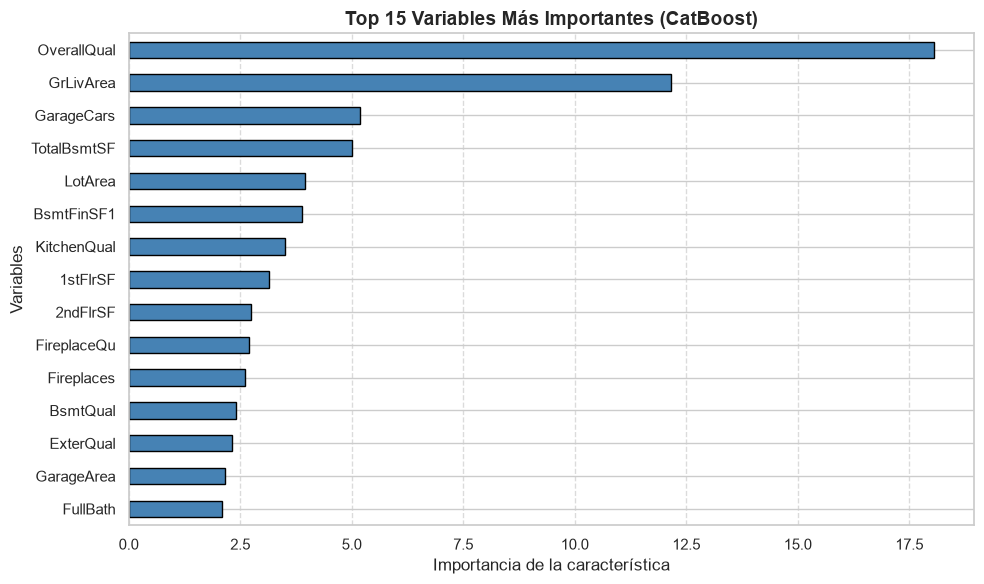

In [ ]:
# TODO: completa esta celda
# `cat_features` espera las posiciones de las columnas, no sus nombres: `columnas.get_loc(...)` te las da.
# CatBoost no admite nulos en las categóricas, por eso hay que rellenarlas con un texto antes de entrenar.

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from catboost import CatBoostRegressor

# 1. Carga de Ames completo (incluyendo variables categóricas de texto)
X_full = ames.data.drop(columns=['Id'], errors='ignore')

cat_cols = X_full.select_dtypes(include=['category', 'object']).columns.tolist()
num_cols = X_full.select_dtypes(include=[np.number]).columns.tolist()

# 2. Imputación: mediana para numéricas, texto "ausente" para categóricas
X_full[num_cols] = SimpleImputer(strategy='median').fit_transform(X_full[num_cols])
X_full[cat_cols] = X_full[cat_cols].fillna("ausente").astype(str)

# 3. Partición Train/Test con el dataset completo
X_train_full, X_test_full, y_train, y_test = train_test_split(X_full, y, test_size=0.2, random_state=42)

# Obtener las posiciones (índices) de las columnas categóricas para CatBoost
cat_indices = [X_train_full.columns.get_loc(col) for col in cat_cols]

# 4. Entrenar CatBoost con características categóricas (~45 segundos)
print("Entrenando CatBoost con variables categóricas (espera unos segundos)...")
cb_completo = CatBoostRegressor(random_state=42, verbose=0)
cb_completo.fit(X_train_full, y_train, cat_features=cat_indices)

# Evaluación y comparación limpia contra el CatBoost numérico de la Parte 1
y_pred_full = cb_completo.predict(X_test_full)
rmse_cb_completo = np.sqrt(mean_squared_error(y_test, y_pred_full))

print(f"\n--- COMPARATIVA DE CATBOOST ---")
print(f"RMSE CatBoost (Solo Numéricas - Parte 1): {rmse_cb_num:.2f}")
print(f"RMSE CatBoost (Con Categóricas - Parte 2): {rmse_cb_completo:.2f}")
print(f"Mejora absoluta por añadir texto: {rmse_cb_num - rmse_cb_completo:.2f} unidades de error.")

# 5. Definición y análisis de importancias (Top 15 features)
importances = pd.Series(cb_completo.feature_importances_, index=X_train_full.columns)
top_15 = importances.sort_values(ascending=False).head(15)

print("\n=== TOP 15 VARIABLES MÁS IMPORTANTES ===")
print(top_15)

n_cat_top15 = top_15.index.isin(cat_cols).sum()
print(f"\nNúmero de variables categóricas entre las 15 más importantes: {n_cat_top15} de 15.")

# --- 6. Gráfico de Importancia de Variables ---
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
# Invertimos el orden para que la más importante quede arriba en el gráfico de barras horizontales
top_15.sort_values(ascending=True).plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Top 15 Variables Más Importantes (CatBoost)', fontsize=14, fontweight='bold')
plt.xlabel('Importancia de la característica', fontsize=12)
plt.ylabel('Variables', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Mis reflexiones finales

*(Escribe aquí tu respuesta)*

- En S05 escribiste que en Ames ganaba el modelo lineal porque la relación era lineal. Hoy cinco ensembles le sacan un 25 %. Reescribe aquella conclusión: ¿qué le pasaba de verdad al árbol único?
- Generaliza lo anterior. Cuando leas o escribas "el modelo X no funciona para este problema", ¿qué deberías comprobar antes de darlo por bueno?
- Aprovechar las columnas de texto mejoró más que cambiar de algoritmo. ¿Qué te dice eso sobre dónde conviene invertir el tiempo en un proyecto real?
- Llevamos cinco sesiones empezando la preparación con `select_dtypes(include=np.number)`. Era una decisión, no un trámite. ¿Qué otras decisiones de este tipo has ido tomando sin pensarlas?
- Has cerrado el bloque con un modelo un 35 % mejor que el primero y completamente opaco. Si el cliente te pregunta "¿por qué esta casa vale 300.000?", ¿qué le respondes? ¿Qué necesitarías para responderle bien? (Guarda la respuesta: es S14.)
- Si mañana empiezas un proyecto nuevo de regresión sobre datos tabulares, ¿por qué modelo empiezas y por qué? Da una respuesta corta y defendible.

---
## Cierre del bloque 2 — Regresión

Cinco sesiones, el mismo tipo de problema y un recorrido que conviene tener ordenado:

| Sesión | Modelo | Qué aportó | Qué costó |
|---|---|---|---|
| S03 | Regresión lineal | Coeficientes que se leen en euros | Solo relaciones rectas |
| S04 | Ridge y Lasso | Estabilidad y selección de variables | Hay que escalar; sigue siendo lineal |
| S05 | Árbol | No linealidad e interacciones, gratis | Inestable; no extrapola |
| S06 | Random Forest | Estabilidad por promediado | Ya no hay nada que dibujar |
| S06 | Boosting moderno | El mejor rendimiento, y rápido | Opaco y con hiperparámetros que importan |

**La regla práctica** para un problema tabular nuevo: empieza por un modelo lineal como referencia —es rápido y te dice si el problema es fácil—, pon al lado un Random Forest por defecto, y si la diferencia entre ambos es grande, invierte en boosting moderno. Si es pequeña, quédate con el lineal y su interpretabilidad.

**Lo que no hemos resuelto y viene después:**

- El modelo final es una caja negra. Explicar sus predicciones una a una es **S14**, con SHAP.
- Hemos usado el conjunto de test más veces de las que deberíamos, y en dos sesiones lo hemos hecho mal a propósito. Ordenarlo bien con pipelines es **S13**.
- Todo lo de hoy vale igual para clasificación, cambiando la métrica. Eso empieza en **S08**.